In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance


In [2]:
from pathlib import Path

# Ruta relativa al repositorio (los notebooks se ejecutan desde notebooks/)
DATA_PATH = Path("..") / "data" / "rendimiento_estudiantes.csv"
# Cargamos el dataset
df = pd.read_csv(DATA_PATH, sep=";")

print("Shape del dataset:", df.shape)
print("Clases objetivo:", df["objetivo"].value_counts())

Shape del dataset: (4424, 37)
Clases objetivo: objetivo
graduado       2209
abandono       1421
matriculado     794
Name: count, dtype: int64


### Selección de variables para la clasificación

Para que la tarea de clasificación tenga verdadero carácter predictivo, se excluyen las variables del segundo semestre. Aunque estas variables podrían mejorar artificialmente las métricas, su uso implicaría basar la predicción en información demasiado cercana al resultado final del estudiante. Por ello, el modelo se entrena únicamente con variables demográficas, socioeconómicas, administrativas y de rendimiento previo al segundo semestre.

In [3]:
# Eliminamos la variable objetivo
X_df = df.drop("objetivo", axis=1)

# Excluimos las variables del segundo semestre para plantear una clasificación predictiva temprana
cols_2sem = [col for col in X_df.columns if "2sem" in col]

X_df = X_df.drop(columns=cols_2sem)

y = df["objetivo"].values

print("Número de variables usadas en clasificación:", X_df.shape[1])
print("Variables excluidas del segundo semestre:", cols_2sem)
print("Shape de X:", X_df.shape)
print("Shape de y:", y.shape)
print("Clases:", np.unique(y))

Número de variables usadas en clasificación: 30
Variables excluidas del segundo semestre: ['asignaturas_2sem_convalidadas', 'asignaturas_2sem_matriculadas', 'asignaturas_2sem_evaluadas', 'asignaturas_2sem_aprobadas', 'nota_media_2sem', 'asignaturas_2sem_sin_evaluacion']
Shape de X: (4424, 30)
Shape de y: (4424,)
Clases: ['abandono' 'graduado' 'matriculado']


### Codificación de variables categóricas

Las variables categóricas se transforman mediante codificación dummy (`one-hot encoding`). Se utiliza `drop_first=True` para evitar redundancia entre categorías y reducir colinealidad innecesaria en los modelos lineales.

In [4]:
# Convertimos las variables categóricas a variables dummy
X_encoded = pd.get_dummies(X_df, drop_first=True)

print("Shape original:", X_df.shape)
print("Shape codificado:", X_encoded.shape)

Shape original: (4424, 30)
Shape codificado: (4424, 232)


In [5]:
# train/test split 
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (3539, 232) (3539,)
Test: (885, 232) (885,)


### Modelo base 1: Regresión logística

Se utiliza regresión logística como modelo base por ser un método lineal, interpretable y competitivo en problemas multiclase. Dado que este modelo es sensible a la escala de las variables, se aplica estandarización antes del entrenamiento.

In [6]:
# Pipeline: escalado + modelo
pipeline_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

# Entrenamiento
pipeline_lr.fit(X_train, y_train)

# Predicción
y_pred_lr = pipeline_lr.predict(X_test)

print("=== Logistic Regression (Pipeline) ===")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("F1 macro:", f1_score(y_test, y_pred_lr, average="macro"))
print(classification_report(y_test, y_pred_lr))

=== Logistic Regression (Pipeline) ===
Accuracy: 0.735593220338983
F1 macro: 0.6504173695494296
              precision    recall  f1-score   support

    abandono       0.77      0.74      0.75       284
    graduado       0.79      0.89      0.83       442
 matriculado       0.44      0.31      0.37       159

    accuracy                           0.74       885
   macro avg       0.66      0.65      0.65       885
weighted avg       0.72      0.74      0.72       885



### Modelo base 2: Árbol de decisión

Como segundo enfoque se emplea un árbol de decisión, que permite capturar relaciones no lineales y posibles interacciones entre variables sin necesidad de escalado previo.

In [7]:
# Los árboles no requieren escalado y pueden capturar relaciones no lineales.

tree = DecisionTreeClassifier(max_depth=5, random_state=42)
tree.fit(X_train, y_train)

y_pred_tree = tree.predict(X_test)

print("=== Decision Tree ===")
print("Accuracy:", accuracy_score(y_test, y_pred_tree))
print("F1 macro:", f1_score(y_test, y_pred_tree, average="macro"))
print(classification_report(y_test, y_pred_tree))

=== Decision Tree ===
Accuracy: 0.7254237288135593
F1 macro: 0.6087564926809778
              precision    recall  f1-score   support

    abandono       0.78      0.68      0.73       284
    graduado       0.74      0.94      0.83       442
 matriculado       0.44      0.19      0.27       159

    accuracy                           0.73       885
   macro avg       0.65      0.61      0.61       885
weighted avg       0.70      0.73      0.70       885



### Modelo base 3: Random Forest

Finalmente, se entrena un Random Forest, que reduce la varianza de un único árbol y suele ofrecer un mejor equilibrio entre capacidad predictiva y robustez.

In [8]:
# Random Forest combina múltiples árboles para mejorar estabilidad y capacidad predictiva.

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("=== Random Forest ===")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("F1 macro:", f1_score(y_test, y_pred_rf, average="macro"))
print(classification_report(y_test, y_pred_rf))

=== Random Forest ===
Accuracy: 0.7378531073446327
F1 macro: 0.6240908923857953
              precision    recall  f1-score   support

    abandono       0.76      0.72      0.74       284
    graduado       0.75      0.94      0.83       442
 matriculado       0.52      0.21      0.30       159

    accuracy                           0.74       885
   macro avg       0.68      0.62      0.62       885
weighted avg       0.71      0.74      0.71       885



### Validación cruzada de los modelos base

Para comparar de forma más robusta los modelos base, se aplica validación cruzada estratificada con 5 particiones. La métrica utilizada es `F1_macro`, ya que se trata de un problema multiclase y esta medida penaliza desequilibrios en el rendimiento entre clases. En el caso de la regresión logística, el escalado se incluye dentro de un `Pipeline` para evitar fuga de información entre folds.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pipe_lr_cv = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

tree_cv = DecisionTreeClassifier(max_depth=5, random_state=42)
rf_cv = RandomForestClassifier(n_estimators=100, random_state=42)

# MEJOR
scores_lr = cross_val_score(pipe_lr_cv, X_train, y_train, cv=cv, scoring="f1_macro")
scores_tree = cross_val_score(tree_cv, X_encoded, y, cv=cv, scoring="f1_macro")
scores_rf = cross_val_score(rf_cv, X_encoded, y, cv=cv, scoring="f1_macro")

print("=== Validación cruzada (F1 macro) ===")
print(f"Logistic Regression: media = {scores_lr.mean():.4f}, std = {scores_lr.std():.4f}")
print(f"Decision Tree:       media = {scores_tree.mean():.4f}, std = {scores_tree.std():.4f}")
print(f"Random Forest:       media = {scores_rf.mean():.4f}, std = {scores_rf.std():.4f}")

=== Validación cruzada (F1 macro) ===
Logistic Regression: media = 0.6635, std = 0.0069
Decision Tree:       media = 0.5935, std = 0.0366
Random Forest:       media = 0.6213, std = 0.0098


### Efecto del desbalanceo de clases

Se compara el rendimiento del Random Forest con y sin ponderación de clases (`class_weight='balanced'`),
para cuantificar el impacto del desbalanceo en la clase minoritaria *matriculado*.

=== Sin class_weight ===
              precision    recall  f1-score   support

    abandono       0.76      0.72      0.74       284
    graduado       0.75      0.94      0.83       442
 matriculado       0.52      0.21      0.30       159

    accuracy                           0.74       885
   macro avg       0.68      0.62      0.62       885
weighted avg       0.71      0.74      0.71       885

F1 macro: 0.624

=== Con class_weight='balanced' ===
              precision    recall  f1-score   support

    abandono       0.76      0.69      0.73       284
    graduado       0.73      0.94      0.82       442
 matriculado       0.40      0.16      0.23       159

    accuracy                           0.72       885
   macro avg       0.63      0.60      0.59       885
weighted avg       0.68      0.72      0.68       885

F1 macro: 0.592



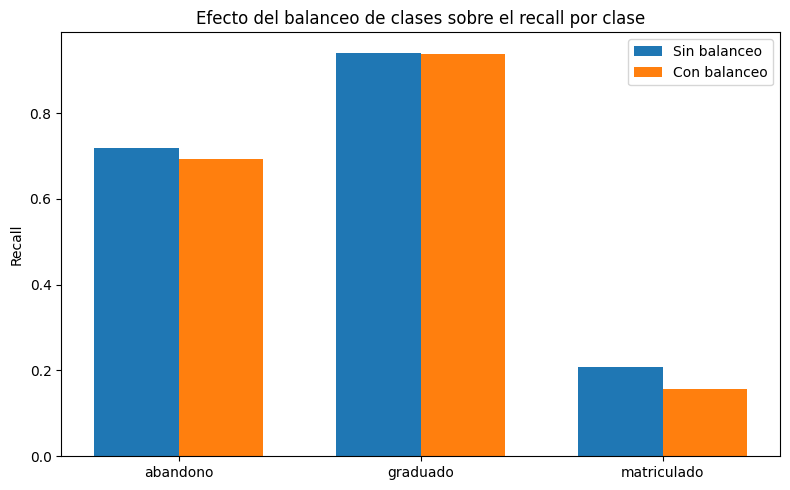

In [10]:
# RF sin balanceo (ya entrenado)
rf_sin = RandomForestClassifier(n_estimators=100, random_state=42)
rf_sin.fit(X_train, y_train)
y_pred_sin = rf_sin.predict(X_test)

# RF con balanceo
rf_con = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42)
rf_con.fit(X_train, y_train)
y_pred_con = rf_con.predict(X_test)

# Comparación de métricas por clase
print("=== Sin class_weight ===")
print(classification_report(y_test, y_pred_sin))
print(f"F1 macro: {f1_score(y_test, y_pred_sin, average='macro'):.3f}\n")

print("=== Con class_weight='balanced' ===")
print(classification_report(y_test, y_pred_con))
print(f"F1 macro: {f1_score(y_test, y_pred_con, average='macro'):.3f}\n")

# Visualización comparativa del recall por clase
clases = ["abandono", "graduado", "matriculado"]
recall_sin = [classification_report(y_test, y_pred_sin, output_dict=True)[c]["recall"] for c in clases]
recall_con = [classification_report(y_test, y_pred_con, output_dict=True)[c]["recall"] for c in clases]

x = np.arange(len(clases))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width/2, recall_sin, width, label="Sin balanceo")
ax.bar(x + width/2, recall_con, width, label="Con balanceo")
ax.set_xticks(x)
ax.set_xticklabels(clases)
ax.set_ylabel("Recall")
ax.set_title("Efecto del balanceo de clases sobre el recall por clase")
ax.legend()
plt.tight_layout()
plt.show()

In [11]:
# Ajuste de hiperparámetros - Logistic Regression
pipe_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

param_grid_lr = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__penalty": ["l2"],
    "model__solver": ["lbfgs"],
    "model__class_weight": [None, "balanced"]
}

grid_lr = GridSearchCV(
    pipe_lr,
    param_grid=param_grid_lr,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

grid_lr.fit(X_train, y_train)

print("Mejores parámetros Logistic Regression:")
print(grid_lr.best_params_)
print("Mejor F1_macro CV:", grid_lr.best_score_)

lr_best = grid_lr.best_estimator_

Mejores parámetros Logistic Regression:
{'model__C': 1, 'model__class_weight': 'balanced', 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
Mejor F1_macro CV: 0.6626465852056379


In [12]:
# Ajuste de hiperparámetros - Decision Tree
param_grid_tree = {
    "max_depth": [3, 5, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "class_weight": [None, "balanced"]
}

grid_tree = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=param_grid_tree,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

grid_tree.fit(X_train, y_train)

print("Mejores parámetros Decision Tree:")
print(grid_tree.best_params_)
print("Mejor F1_macro CV:", grid_tree.best_score_)

tree_best = grid_tree.best_estimator_

Mejores parámetros Decision Tree:
{'class_weight': 'balanced', 'max_depth': 5, 'min_samples_leaf': 5, 'min_samples_split': 2}
Mejor F1_macro CV: 0.6227889053620688


In [13]:
param_dist_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "class_weight": [None, "balanced"]
}

random_rf = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    param_distributions=param_dist_rf,
    n_iter=12,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    random_state=42
)

random_rf.fit(X_train, y_train)

print("Mejores parámetros Random Forest:")
print(random_rf.best_params_)
print("Mejor F1_macro CV:", random_rf.best_score_)

rf_best = random_rf.best_estimator_

Mejores parámetros Random Forest:
{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 10, 'class_weight': 'balanced'}
Mejor F1_macro CV: 0.6757956269825346


### Evaluación final de los modelos optimizados

Una vez ajustados los hiperparámetros, se evalúan en el conjunto de test los mejores modelos encontrados. Esta comparación permite verificar si la mejora observada en validación cruzada se mantiene sobre datos no vistos.

In [14]:
# Evaluación final en test de los mejores modelos encontrados
y_pred_lr_best = lr_best.predict(X_test)
y_pred_tree_best = tree_best.predict(X_test)
y_pred_rf_best = rf_best.predict(X_test)

print("=== Logistic Regression optimizada ===")
print("Accuracy:", accuracy_score(y_test, y_pred_lr_best))
print("F1 macro:", f1_score(y_test, y_pred_lr_best, average="macro"))
print(classification_report(y_test, y_pred_lr_best))

print("=== Decision Tree optimizado ===")
print("Accuracy:", accuracy_score(y_test, y_pred_tree_best))
print("F1 macro:", f1_score(y_test, y_pred_tree_best, average="macro"))
print(classification_report(y_test, y_pred_tree_best))

print("=== Random Forest optimizado ===")
print("Accuracy:", accuracy_score(y_test, y_pred_rf_best))
print("F1 macro:", f1_score(y_test, y_pred_rf_best, average="macro"))
print(classification_report(y_test, y_pred_rf_best))

=== Logistic Regression optimizada ===
Accuracy: 0.6971751412429379
F1 macro: 0.6497896930531897
              precision    recall  f1-score   support

    abandono       0.76      0.68      0.72       284
    graduado       0.84      0.77      0.81       442
 matriculado       0.36      0.51      0.43       159

    accuracy                           0.70       885
   macro avg       0.65      0.66      0.65       885
weighted avg       0.73      0.70      0.71       885

=== Decision Tree optimizado ===
Accuracy: 0.6225988700564972
F1 macro: 0.5989234593226949
              precision    recall  f1-score   support

    abandono       0.80      0.52      0.63       284
    graduado       0.85      0.67      0.75       442
 matriculado       0.30      0.66      0.42       159

    accuracy                           0.62       885
   macro avg       0.65      0.62      0.60       885
weighted avg       0.73      0.62      0.65       885

=== Random Forest optimizado ===
Accuracy: 0.72994

### Comparación de modelos base

La siguiente tabla resume el rendimiento de los tres modelos iniciales sobre el conjunto de test. Se comparan tanto la `accuracy` como `F1_macro`, aunque esta última será la referencia principal por tratarse de un problema multiclase.

In [15]:
resultados = pd.DataFrame({
    "Modelo": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_rf)
    ],
    "F1_macro": [
        f1_score(y_test, y_pred_lr, average="macro"),
        f1_score(y_test, y_pred_tree, average="macro"),
        f1_score(y_test, y_pred_rf, average="macro")
    ]
})

resultados.sort_values(by="F1_macro", ascending=False)

,Modelo,Accuracy,F1_macro
0,Logistic Regression,0.735593,0.650417
2,Random Forest,0.737853,0.624091
1,Decision Tree,0.725424,0.608756


### Comparación de modelos optimizados

Tras el ajuste de hiperparámetros, se comparan de nuevo los modelos para comprobar si la optimización mejora el rendimiento y altera el ranking observado en los modelos base.En este caso, la optimización beneficia especialmente a Random Forest, que pasa a ser el mejor modelo en términos de `F1_macro`. Esto sugiere que un ajuste adecuado de profundidad, tamaño mínimo de hoja y ponderación de clases permite capturar mejor la complejidad del problema sin depender de variables del segundo semestre.

In [16]:
resultados_opt = pd.DataFrame({
    "Modelo": ["Logistic Regression optimizada", "Decision Tree optimizado", "Random Forest optimizado"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr_best),
        accuracy_score(y_test, y_pred_tree_best),
        accuracy_score(y_test, y_pred_rf_best)
    ],
    "F1_macro": [
        f1_score(y_test, y_pred_lr_best, average="macro"),
        f1_score(y_test, y_pred_tree_best, average="macro"),
        f1_score(y_test, y_pred_rf_best, average="macro")
    ]
})

resultados_opt.sort_values(by="F1_macro", ascending=False)

,Modelo,Accuracy,F1_macro
2,Random Forest optimizado,0.729944,0.680386
0,Logistic Regression optimizada,0.697175,0.649790
1,Decision Tree optimizado,0.622599,0.598923


### Interpretabilidad del mejor modelo

Para interpretar el modelo con mejor rendimiento se analiza la importancia de variables del Random Forest optimizado. Este análisis no debe interpretarse en términos causales, pero sí permite identificar qué factores contribuyen más a la predicción de la situación final del estudiante.Las variables más relevantes del modelo muestran que el desempeño académico temprano, especialmente el número de asignaturas aprobadas y la nota media del primer semestre, constituye la principal señal predictiva de la situación final del estudiante.

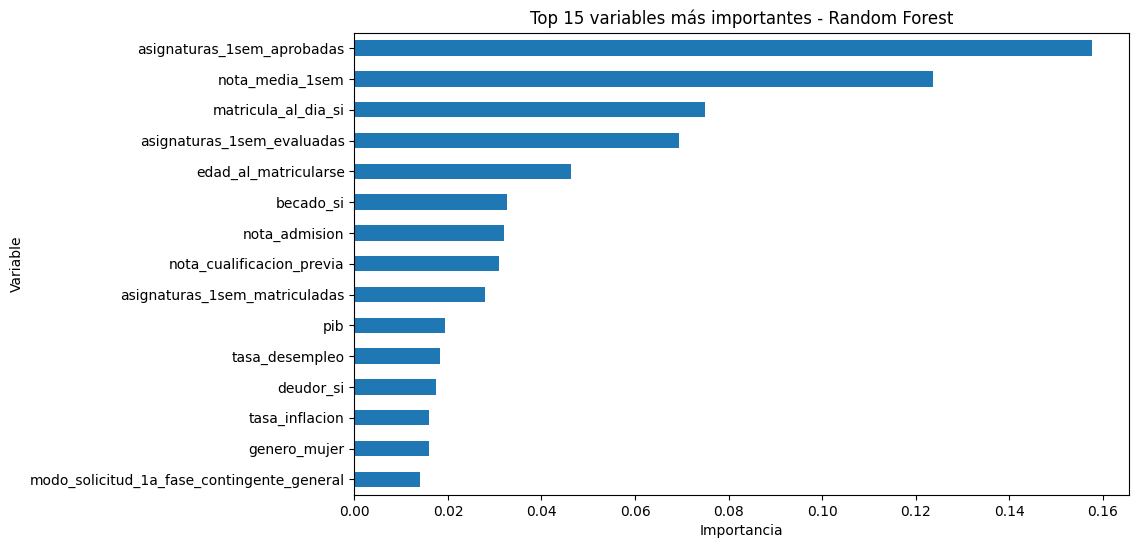

asignaturas_1sem_aprobadas                    0.157806
nota_media_1sem                               0.123812
matricula_al_dia_si                           0.074985
asignaturas_1sem_evaluadas                    0.069484
edad_al_matricularse                          0.046290
becado_si                                     0.032582
nota_admision                                 0.031907
nota_cualificacion_previa                     0.030838
asignaturas_1sem_matriculadas                 0.028004
pib                                           0.019410
tasa_desempleo                                0.018328
deudor_si                                     0.017433
tasa_inflacion                                0.016050
genero_mujer                                  0.016030
modo_solicitud_1a_fase_contingente_general    0.013977
dtype: float64

In [17]:
importancias = pd.Series(rf_best.feature_importances_, index=X_encoded.columns)
importancias = importancias.sort_values(ascending=False)

top15 = importancias.head(15)

plt.figure(figsize=(10, 6))
top15.sort_values().plot(kind="barh")
plt.title("Top 15 variables más importantes - Random Forest")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.show()

top15

### Permutation Importance

Para validar las importancias internas del Random Forest, se calcula la *permutation importance*
sobre el conjunto de test. A diferencia de las importancias basadas en impureza, esta métrica
mide la caída real de F1 macro al permutar aleatoriamente cada variable.

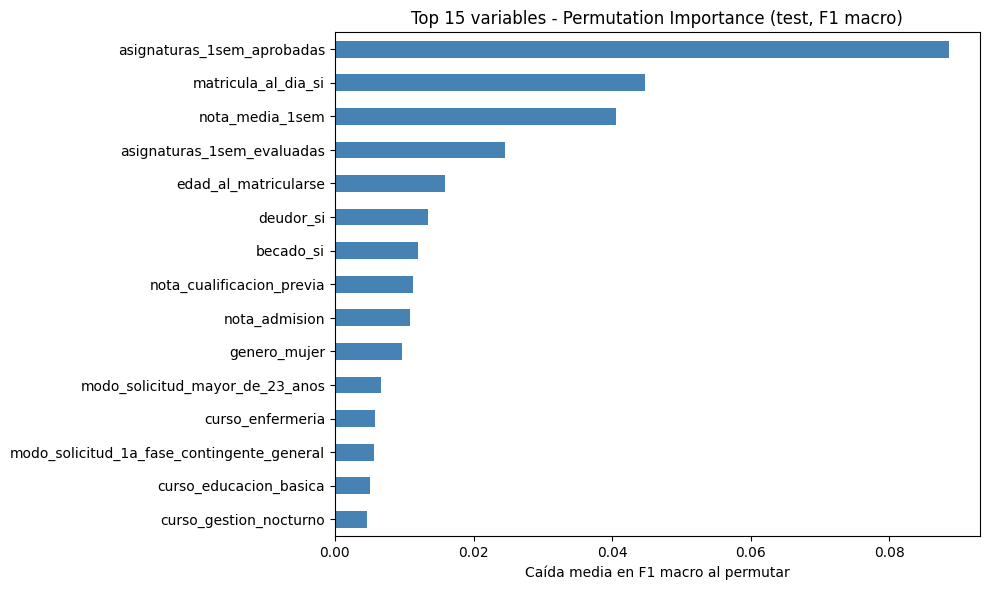

Top 10 variables por permutation importance:
asignaturas_1sem_aprobadas    0.0886
matricula_al_dia_si           0.0448
nota_media_1sem               0.0405
asignaturas_1sem_evaluadas    0.0245
edad_al_matricularse          0.0159
deudor_si                     0.0134
becado_si                     0.0120
nota_cualificacion_previa     0.0113
nota_admision                 0.0109
genero_mujer                  0.0096
dtype: float64


In [18]:
result = permutation_importance(
    rf_best, X_test, y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_imp = pd.Series(result.importances_mean, index=X_encoded.columns)
perm_imp = perm_imp.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
perm_imp.sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 15 variables - Permutation Importance (test, F1 macro)")
plt.xlabel("Caída media en F1 macro al permutar")
plt.tight_layout()
plt.show()

print("Top 10 variables por permutation importance:")
print(perm_imp.head(10).round(4))

### Matriz de confusión del mejor modelo

La matriz de confusión permite analizar en qué clases acierta y en cuáles falla más el modelo final. Este análisis resulta especialmente útil en problemas multiclase, ya que permite detectar si alguna categoría presenta mayor ambigüedad que las demás.

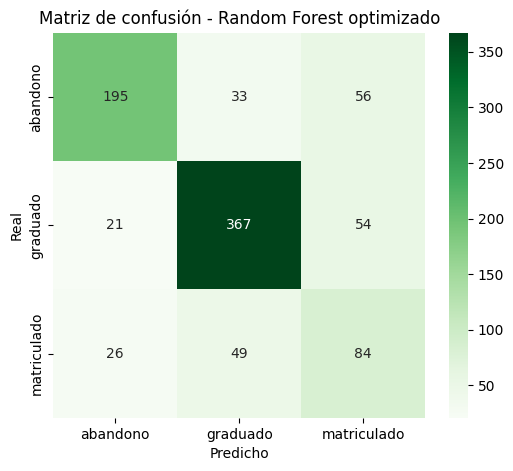

In [19]:
labels = ["abandono", "graduado", "matriculado"]
cm_rf = confusion_matrix(y_test, y_pred_rf_best, labels=labels)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Matriz de confusión - Random Forest optimizado")
plt.xlabel("Predicho")
plt.ylabel("Real")
plt.show()

## Conclusión

La clasificación de la situación final del estudiante se ha planteado utilizando únicamente variables disponibles antes del segundo semestre, con el fin de preservar el carácter predictivo real de la tarea. Bajo este enfoque, el modelo con mejor rendimiento final es Random Forest optimizado, que alcanza el mayor valor de `F1_macro` y ofrece un buen equilibrio entre precisión global y capacidad para distinguir las tres clases.

El análisis muestra que las variables más influyentes están relacionadas principalmente con el rendimiento del primer semestre, junto con algunos factores administrativos y de contexto previo. Esto sugiere que la trayectoria académica temprana aporta una señal muy relevante para anticipar el resultado final del estudiante.

No obstante, la clase `matriculado` sigue siendo la más difícil de predecir, lo que indica que representa una situación intermedia menos definida que `abandono` o `graduado`. En consecuencia, aunque el modelo resulta útil para detección temprana, sus predicciones deben interpretarse como apoyo a la decisión y no como una determinación concluyente del futuro académico del alumno.

### Modelo final seleccionado

Tras comparar los tres modelos base y sus versiones optimizadas mediante búsqueda de hiperparámetros, el modelo seleccionado es el **Random Forest optimizado** con `class_weight='balanced'`, `max_depth=10`, `min_samples_leaf=1`, `min_samples_split=2` y `n_estimators=200`.

Obtiene un **F1-macro de 0.6804** y una accuracy de 0.7299 en el conjunto de test, siendo el mejor en ambas métricas. Frente a la Regresión Logística (F1-macro 0.6498) y el Árbol de Decisión (F1-macro 0.5989), el Random Forest ofrece el mayor equilibrio entre las tres clases, incluyendo la más difícil de predecir (`matriculado`, F1=0.48).

Se elige **F1-macro** como métrica principal porque el dataset está desbalanceado (50% graduado, 32% abandono, 18% matriculado) y la accuracy puede resultar engañosa al favorecer la clase mayoritaria. F1-macro penaliza por igual los errores en cada clase, lo que resulta más adecuado cuando el coste de confundir abandono con graduado es alto.


In [20]:
# === MODELO FINAL SELECCIONADO ===
print("Modelo seleccionado: Random Forest optimizado")
print(f"Accuracy en test:  {accuracy_score(y_test, y_pred_rf_best):.4f}")
print(f"F1-macro en test:  {f1_score(y_test, y_pred_rf_best, average='macro'):.4f}")
print()
print("Justificación del modelo elegido:")
f1_rf = f1_score(y_test, y_pred_rf_best, average="macro")
f1_lr = f1_score(y_test, y_pred_lr_best, average="macro")
f1_tree = f1_score(y_test, y_pred_tree_best, average="macro")
print(f"  - Mayor F1-macro en test entre todos los modelos evaluados ({f1_rf:.4f})")
print(f"  - Supera a Logistic Regression optimizada (F1-macro {f1_lr:.4f}) y Decision Tree ({f1_tree:.4f})")
print("  - Mejor equilibrio entre las tres clases, incluida la minoritaria 'matriculado'")
print("  - Robusto frente al desbalanceo gracias a class_weight='balanced'")


Modelo seleccionado: Random Forest optimizado
Accuracy en test:  0.7299
F1-macro en test:  0.6804

Justificación del modelo elegido:
  - Mayor F1-macro en test entre todos los modelos evaluados (0.6804)
  - Supera a Logistic Regression optimizada (F1-macro 0.6498) y Decision Tree (0.5989)
  - Mejor equilibrio entre las tres clases, incluida la minoritaria 'matriculado'
  - Robusto frente al desbalanceo gracias a class_weight='balanced'
